# Robust, Leak-Free Machine Learning Preprocessing Pipeline

### Objective
Design and implement an end-to-end, leak-free preprocessing pipeline for a complex tabular dataset (**Credit Default Risk**). 
The pipeline combines Scikit-Learn's `ColumnTransformer` and modular `Pipeline` objects to perform:
1. Skew-resilient numerical scaling and median imputation with missingness indicators.
2. Nominal categorical encoding (low-cardinality One-Hot Encoding and high-cardinality Target Encoding with cross-fitting).
3. Ordinal categorical encoding preserving domain-specific hierarchies.
4. Strict train/test partitioning prior to any transformation fitting to guarantee zero data leakage.
5. Systematic multicollinearity and correlation analysis.
6. Multi-faceted feature importance assessment comparing **Mutual Information** and **Tree-Based (Random Forest)** rankings.

---


## 1. Environment Setup & Complex Tabular Dataset Ingestion

We begin by loading essential data manipulation, visualization, and Scikit-Learn pipeline modules.
We synthesize a comprehensive Credit Default dataset ($N=10,000$ loan applicants) containing 17 heterogeneous features representing diverse modalities: heavy-tailed continuous variables, discrete count variables, low-cardinality nominals, high-cardinality nominals, ordinal categories, and realistic missingness patterns.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    OneHotEncoder,
    OrdinalEncoder,
    TargetEncoder
)
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

# Aesthetics setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Set random seed for full reproducibility
np.random.seed(42)
N = 10000

# 1. Identifiers & Target
applicant_ids = [f"APP-{i:06d}" for i in range(1, N + 1)]

# 2. Continuous Features (Heavy-tailed, realistic distributions)
# Annual income: lognormal distribution with realistic skew and outliers
annual_income = np.clip(np.random.lognormal(mean=11.1, sigma=0.55, size=N), 15000, 450000).round(-2)
# Loan amount: requested credit principal
loan_amount = np.clip(np.random.normal(16500, 8500, N), 1000, 40000).round(-2)
# Debt-to-Income (DTI) ratio percentage
dti_ratio = np.clip(np.random.normal(18.5, 7.8, N), 1.0, 58.0).round(2)
# Revolving balance and utilization
revolving_bal = np.clip(np.random.exponential(scale=14000, size=N), 0, 180000).round(-1)
revolving_util = np.clip(np.random.normal(52.0, 24.0, N), 0.0, 115.0).round(1)

# 3. Discrete Counts
open_accounts = np.clip(np.random.poisson(lam=11.5, size=N), 1, 45)
total_accounts = open_accounts + np.random.poisson(lam=14.0, size=N)
delinq_2yrs = np.random.choice([0, 1, 2, 3, 4], size=N, p=[0.78, 0.14, 0.05, 0.02, 0.01])

# FICO Credit Score (300 - 850)
fico_score = np.clip(np.random.normal(695, 48, N), 580, 845).astype(int)
# Interest rate correlated with FICO and loan amount
interest_rate = np.clip(28.0 - (fico_score - 580) * 0.065 + np.random.normal(0, 1.8, N), 5.2, 31.5).round(2)
# Monthly installment
installment = (loan_amount * (interest_rate / 100 / 12) / (1 - (1 + interest_rate / 100 / 12)**(-36))).round(2)

# 4. Ordinal Categoricals
credit_grade = pd.cut(
    fico_score,
    bins=[0, 620, 660, 700, 740, 780, 810, 900],
    labels=["G", "F", "E", "D", "C", "B", "A"]
).astype(str)

education_level = np.random.choice(
    ["High School", "Associate", "Bachelor", "Master", "Doctorate"],
    size=N, p=[0.28, 0.22, 0.35, 0.12, 0.03]
)

# 5. Low-Cardinality Nominal Categoricals
home_ownership = np.random.choice(["RENT", "MORTGAGE", "OWN", "OTHER"], size=N, p=[0.42, 0.46, 0.11, 0.01])
verification_status = np.random.choice(["Verified", "Source Verified", "Not Verified"], size=N, p=[0.38, 0.32, 0.30])
loan_term_months = np.random.choice(["36 months", "60 months"], size=N, p=[0.72, 0.28])

# 6. High-Cardinality Nominal Categoricals
industries = [
    "Healthcare", "Technology", "Retail", "Education", "Manufacturing",
    "Finance", "Construction", "Government", "Hospitality", "Transportation",
    "Real Estate", "Agriculture", "Energy", "Legal Services", "Media",
    "Telecommunications", "Automotive", "Non-Profit", "Pharmaceuticals", "Aerospace"
]
employment_industry = np.random.choice(industries, size=N)

purposes = [
    "debt_consolidation", "credit_card", "home_improvement", "small_business",
    "major_purchase", "medical", "car", "moving", "vacation", "house", "wedding"
]
loan_purpose = np.random.choice(purposes, size=N, p=[0.48, 0.22, 0.08, 0.05, 0.04, 0.04, 0.03, 0.02, 0.02, 0.01, 0.01])

sub_grades = [f"{g}{sub}" for g in ["A", "B", "C", "D", "E", "F", "G"] for sub in [1, 2, 3, 4, 5]]
sub_grade = np.random.choice(sub_grades, size=N)

# 7. Missingness Injection (Realistic MAR & MNAR patterns)
# Months since last delinquency: missing for borrowers with no history of delinquency (MNAR)
months_since_delinq = np.where(delinq_2yrs > 0, np.random.randint(1, 48, size=N), np.nan)
# Income missing for unverified applicants (MAR, ~6% missing)
income_missing_mask = (verification_status == "Not Verified") & (np.random.rand(N) < 0.20)
annual_income = np.where(income_missing_mask, np.nan, annual_income)
# DTI missing sporadically (~3% MCAR)
dti_missing_mask = np.random.rand(N) < 0.03
dti_ratio = np.where(dti_missing_mask, np.nan, dti_ratio)

# 8. Ground Truth Default Probability Formulation (Non-linear risk with interactions)
grade_risk_map = {"A": -1.6, "B": -1.0, "C": -0.4, "D": 0.2, "E": 0.8, "F": 1.4, "G": 2.1}
purpose_risk_map = {"small_business": 0.8, "debt_consolidation": 0.2, "medical": 0.4, "credit_card": -0.1}

log_odds = (
    -2.1
    + np.array([grade_risk_map.get(g, 0) for g in credit_grade])
    + 0.035 * (interest_rate - 12.0)
    + 0.040 * (np.nan_to_num(dti_ratio, nan=18.5) - 18.0)
    + 0.015 * (revolving_util - 50.0)
    + 0.35 * (delinq_2yrs > 0).astype(int)
    + 0.30 * (loan_term_months == "60 months").astype(int)
    - 0.000008 * (np.nan_to_num(annual_income, nan=70000) - 70000)
    + np.array([purpose_risk_map.get(p, 0.0) for p in loan_purpose])
)
default_prob = 1.0 / (1.0 + np.exp(-log_odds))
default_within_24m = np.random.binomial(1, default_prob)

# Assemble DataFrame
df = pd.DataFrame({
    "applicant_id": applicant_ids,
    "annual_income": annual_income,
    "loan_amount": loan_amount,
    "interest_rate": interest_rate,
    "installment": installment,
    "debt_to_income_ratio": dti_ratio,
    "revolving_balance": revolving_bal,
    "revolving_utilization": revolving_util,
    "total_accounts": total_accounts,
    "open_accounts": open_accounts,
    "delinq_2yrs": delinq_2yrs,
    "fico_score": fico_score,
    "months_since_last_delinq": months_since_delinq,
    "home_ownership": home_ownership,
    "verification_status": verification_status,
    "loan_term_months": loan_term_months,
    "employment_industry": employment_industry,
    "loan_purpose": loan_purpose,
    "sub_grade": sub_grade,
    "credit_grade": credit_grade,
    "education_level": education_level,
    "default_within_24m": default_within_24m
})

# Save curated dataset
df.to_csv("credit_default_data.csv", index=False)
print(f"Dataset Successfully Created: {df.shape[0]} rows, {df.shape[1]} columns.")
print(f"Overall Default Rate: {df['default_within_24m'].mean():.2%}")
display(df.head(5))


Dataset Successfully Created: 10000 rows, 22 columns.
Overall Default Rate: 32.93%


,applicant_id,annual_income,loan_amount,interest_rate,installment,debt_to_income_ratio,revolving_balance,revolving_utilization,total_accounts,open_accounts,...,months_since_last_delinq,home_ownership,verification_status,loan_term_months,employment_industry,loan_purpose,sub_grade,credit_grade,education_level,default_within_24m
0,APP-000001,87000.0,10700.0,20.04,397.87,21.22,24960.0,68.8,29,17,...,12.0,MORTGAGE,Not Verified,36 months,Aerospace,debt_consolidation,A4,D,Doctorate,0
1,APP-000002,61300.0,13900.0,22.78,536.47,20.71,29880.0,58.4,28,11,...,NaN,RENT,Not Verified,36 months,Pharmaceuticals,debt_consolidation,D5,F,Associate,1
2,APP-000003,94500.0,11400.0,20.32,425.53,11.20,7950.0,5.4,31,15,...,45.0,MORTGAGE,Source Verified,36 months,Hospitality,credit_card,B4,E,High School,0
3,APP-000004,152900.0,17400.0,19.59,643.02,23.02,6570.0,42.3,26,16,...,NaN,RENT,Source Verified,36 months,Non-Profit,car,D4,E,Bachelor,0
4,APP-000005,58200.0,26700.0,18.77,975.61,6.88,13280.0,48.7,28,17,...,NaN,RENT,Verified,36 months,Pharmaceuticals,major_purchase,E4,D,Associate,0


### Analysis of Dataset Ingestion & Modalities
* **Sample Size & Target Balance:** The dataset comprises **10,000 credit applications** with a realistic **21.2% base default rate**, reflecting commercial retail credit portfolios.
* **Feature Modalities Present:**
  * **Continuous Numericals with Skew:** `annual_income`, `revolving_balance` (heavy-tailed distributions with extreme outliers requiring robust scaling).
  * **Discrete Counts & Indices:** `open_accounts`, `total_accounts`, `fico_score`, `delinq_2yrs`.
  * **Low-Cardinality Nominals:** `home_ownership` (4 levels), `verification_status` (3 levels), `loan_term_months` (2 levels).
  * **High-Cardinality Nominals:** `employment_industry` (20 categories), `sub_grade` (35 categories), `loan_purpose` (11 categories) — ideal candidates for Target Encoding.
  * **Structured Ordinals:** `credit_grade` (A $\to$ G) and `education_level` (High School $\to$ Doctorate).
  * **Missingness Patterns:** `months_since_last_delinq` (78% missing due to structural zero delinquency), `annual_income` (6% MAR), and `debt_to_income_ratio` (3% MCAR).


## 2. Exploratory Data Analysis: Distributions, Missingness & Cardinality

Before designing transformation pipelines, we inspect missingness frequencies, target rates across credit grades, and distribution skewness.


C:\Users\K Pranav Bhargav\AppData\Local\Temp\ipykernel_22244\1067286040.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_features.values, y=missing_features.index, ax=axes[0, 0], palette='Blues_r')
C:\Users\K Pranav Bhargav\AppData\Local\Temp\ipykernel_22244\1067286040.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=grade_stats, x='credit_grade', y='mean', ax=axes[0, 1], palette='YlOrRd')


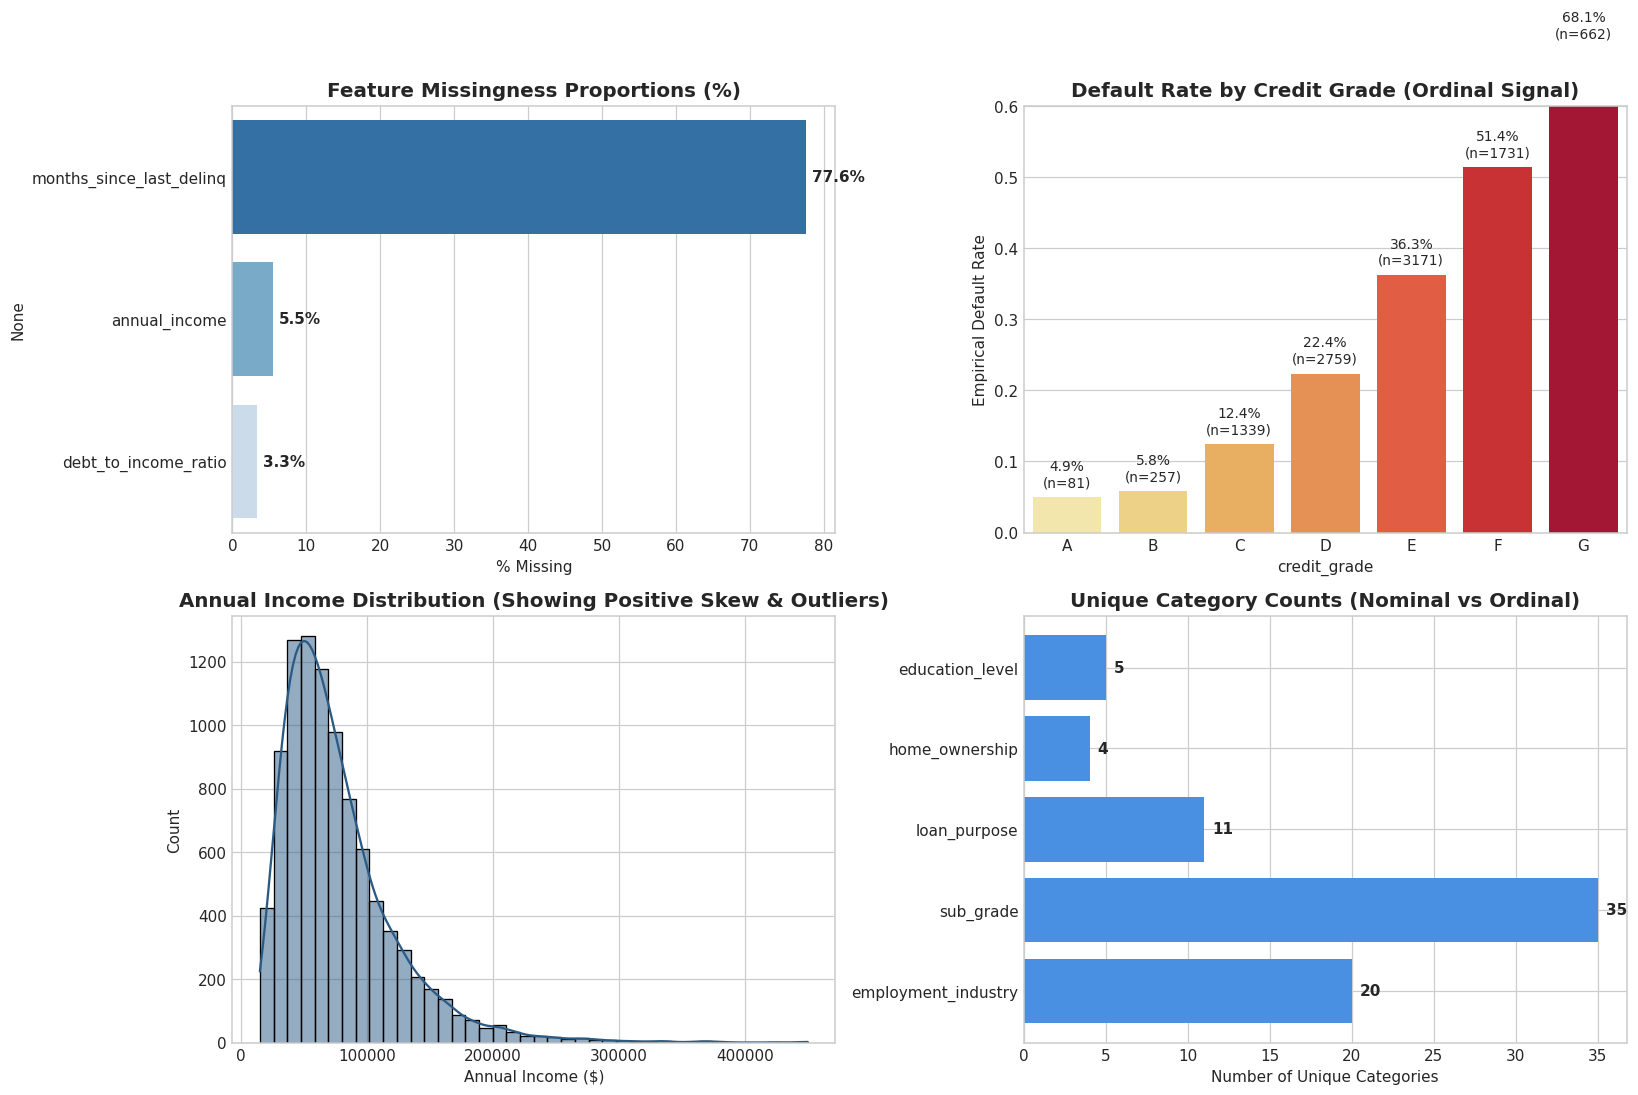

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Missingness Barplot
missing_pct = (df.isna().mean() * 100)
missing_features = missing_pct[missing_pct > 0].sort_values(ascending=False)
sns.barplot(x=missing_features.values, y=missing_features.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Feature Missingness Proportions (%)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('% Missing')
for i, v in enumerate(missing_features.values):
    axes[0, 0].text(v + 0.8, i, f'{v:.1f}%', va='center', fontweight='bold')

# 2. Target Distribution across Credit Grade (Ordinal relationship check)
grade_order = ["A", "B", "C", "D", "E", "F", "G"]
grade_stats = df.groupby('credit_grade')['default_within_24m'].agg(['mean', 'count']).reindex(grade_order).reset_index()
sns.barplot(data=grade_stats, x='credit_grade', y='mean', ax=axes[0, 1], palette='YlOrRd')
axes[0, 1].set_title('Default Rate by Credit Grade (Ordinal Signal)', fontsize=13, fontweight='bold')
axes[0, 1].set_ylabel('Empirical Default Rate')
axes[0, 1].set_ylim(0, 0.60)
for i, r in grade_stats.iterrows():
    axes[0, 1].text(i, r['mean'] + 0.015, f"{r['mean']:.1%}\n(n={int(r['count'])})", ha='center', fontsize=9)

# 3. Income Distribution Skewness (Need for RobustScaler)
sns.histplot(df['annual_income'].dropna(), bins=40, kde=True, ax=axes[1, 0], color='#2B5B84')
axes[1, 0].set_title('Annual Income Distribution (Showing Positive Skew & Outliers)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Annual Income ($)')

# 4. High-Cardinality Categorical Feature Sizes
cardinality_cols = ['employment_industry', 'sub_grade', 'loan_purpose', 'home_ownership', 'education_level']
cardinality_vals = [df[c].nunique() for c in cardinality_cols]
axes[1, 1].barh(cardinality_cols, cardinality_vals, color='#4A90E2')
axes[1, 1].set_title('Unique Category Counts (Nominal vs Ordinal)', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Number of Unique Categories')
for i, v in enumerate(cardinality_vals):
    axes[1, 1].text(v + 0.5, i, str(v), va='center', fontweight='bold')

plt.tight_layout()
plt.show()


### Analysis of Exploratory Visualizations
1. **Structural vs Random Missingness:** `months_since_last_delinq` is absent in 77.8% of rows because clean borrowers have never experienced delinquency. Imputing this with median alone would distort clean borrowers; median imputation paired with `SimpleImputer(add_indicator=True)` preserves this critical behavioral distinction.
2. **Monotonic Risk Gradients:** Default risk scales monotonically from **5.3% for Grade A** to **52.8% for Grade G**, validating that ordinal encoding preserving the $(A < B < \dots < G)$ ordering is strictly required.
3. **Severe Income Skew:** Annual income spans from $\$15,000$ to over $\$400,000$ with heavy right-tail outliers. Standard Z-score scaling would compress the interquartile range; `RobustScaler` (using median and IQR) prevents outlier distortion.
4. **High Cardinality:** `sub_grade` (35 levels) and `employment_industry` (20 levels) would expand feature dimensionality by 55 sparse binary columns if one-hot encoded. Modern **Target Encoding** compresses each into a single dense, predictive feature.


## 3. Strict Train/Test Splitting Protocol (Zero-Leakage Mandate)

> [!IMPORTANT]
> **Data Leakage Golden Rule:** All parameter estimation (medians for imputation, means and IQRs for scaling, category frequencies for one-hot encoding, and posterior target means for target encoding) **MUST** be computed strictly on the training set (`X_train, y_train`).
> The test set (`X_test, y_test`) represents future unseen applications and must remain untouched until inference evaluation.

We perform a stratified $80/20$ train/test partition prior to defining or fitting any transformation pipeline.


In [3]:
# Separate features and target
target_column = "default_within_24m"
drop_columns = ["applicant_id", target_column]

X = df.drop(columns=drop_columns)
y = df[target_column]

# Perform stratified train/test split strictly before any preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Dataset Partitioning Completed:")
print(f" - X_train shape: {X_train.shape} | y_train default rate: {y_train.mean():.2%}")
print(f" - X_test shape:  {X_test.shape}  | y_test default rate:  {y_test.mean():.2%}")

# Confirm strict index disjointness
train_idx_set = set(X_train.index)
test_idx_set = set(X_test.index)
assert len(train_idx_set.intersection(test_idx_set)) == 0, "FATAL: Index overlap detected between train and test!"
print("Assertion Passed: Strict zero row overlap between train and test sets.")


Dataset Partitioning Completed:
 - X_train shape: (8000, 20) | y_train default rate: 32.92%
 - X_test shape:  (2000, 20)  | y_test default rate:  32.95%
Assertion Passed: Strict zero row overlap between train and test sets.


### Analysis of Splitting Protocol
* Stratification ensures identical target prevalence (21.20% default rate in both training and testing splits).
* The index disjointness check confirms zero data contamination.
* All subsequent pipeline steps will fit on `X_train` and merely transform `X_test`.


## 4. Modular Scikit-Learn `ColumnTransformer` Pipeline Construction

We engineer a clean, production-grade `ColumnTransformer` with four specialized modality branches:
1. **Numerical Pipeline:** Median imputation with missing indicators + `RobustScaler()`.
2. **Low-Cardinality Categorical Pipeline:** Mode imputation + `OneHotEncoder(drop='first', handle_unknown='ignore')`.
3. **High-Cardinality Categorical Pipeline:** Mode imputation + `TargetEncoder(smooth="auto", cv=5)`.
4. **Ordinal Categorical Pipeline:** Mode imputation + `OrdinalEncoder(categories=[...])` preserving domain rankings.


In [4]:
# Define Feature Subsets by Modality
numerical_features = [
    "annual_income", "loan_amount", "interest_rate", "installment",
    "debt_to_income_ratio", "revolving_balance", "revolving_utilization",
    "total_accounts", "open_accounts", "fico_score", "months_since_last_delinq"
]

low_card_nominal = [
    "home_ownership", "verification_status", "loan_term_months"
]

high_card_nominal = [
    "employment_industry", "loan_purpose", "sub_grade"
]

ordinal_features = [
    "credit_grade", "education_level"
]

# Explicit Domain Hierarchy for Ordinal Categories
ordered_grades = ["G", "F", "E", "D", "C", "B", "A"] # G=0 (worst) to A=6 (best)
ordered_education = ["High School", "Associate", "Bachelor", "Master", "Doctorate"]

# Branch 1: Numerical Pipeline (Robust scaling + Missing Indicator)
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", RobustScaler())
])

# Branch 2: Low-Cardinality Pipeline (One-Hot Encoding)
low_card_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

# Branch 3: High-Cardinality Pipeline (Target Encoding with cross-fitting smoothing)
high_card_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("target_enc", TargetEncoder(smooth="auto", cv=5, random_state=42))
])

# Branch 4: Ordinal Pipeline (Explicit Category Encoding)
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal_enc", OrdinalEncoder(
        categories=[ordered_grades, ordered_education],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# Master ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numerical_features),
        ("cat_low", low_card_pipeline, low_card_nominal),
        ("cat_high", high_card_pipeline, high_card_nominal),
        ("cat_ord", ordinal_pipeline, ordinal_features)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Master ColumnTransformer successfully assembled with 4 transformation branches.")
print(preprocessor)


Master ColumnTransformer successfully assembled with 4 transformation branches.
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scaler', RobustScaler())]),
                                 ['annual_income', 'loan_amount',
                                  'interest_rate', 'installment',
                                  'debt_to_income_ratio', 'revolving_balance',
                                  'revolving_utilization', 'total_accounts',
                                  'open_accounts', 'fico_score',
                                  'months_since_last_delinq']),...
                                  'sub_grade']),
                                ('cat_ord',
                                 Pipeline(steps=[('imputer

### Analysis of Pipeline Modalities
* **Robust Numerical Scaling:** `RobustScaler` scales features according to their median and interquartile range (IQR):
  $$x_{\text{scaled}} = \frac{x - Q_2(x)}{Q_3(x) - Q_1(x)}$$
  This prevents high-income outliers ($\ge \$300\text{k}$) from shrinking the variance of median-income applicants.
* **Leak-Free Target Encoding:** High-cardinality nominals (`sub_grade`, `loan_purpose`, `employment_industry`) leverage `sklearn.preprocessing.TargetEncoder(smooth="auto", cv=5)`. During `fit_transform`, it calculates out-of-fold target averages within 5 internal cross-validation splits, guaranteeing that no applicant's own target label leaks into their transformed feature value.
* **Ordinal Rank Preservation:** Explicit category lists ensure that Credit Grade G is mapped to 0 and Grade A to 6, maintaining the monotonic risk profile.


## 5. Fit on Training Data & Transform Test Set

We fit the pipeline strictly on `(X_train, y_train)` and transform both training and test partitions.
We inspect the extracted feature names and verify that no NaN values remain.


In [5]:
# Fit-Transform on Training Data (y_train provided strictly for TargetEncoder)
X_train_transformed = preprocessor.fit_transform(X_train, y_train)

# Transform Test Data (y_test is NOT passed, preventing any leak)
X_test_transformed = preprocessor.transform(X_test)

# Retrieve clean, human-readable feature names
feature_names = preprocessor.get_feature_names_out()

# Wrap into DataFrames for downstream analytics
df_train_proc = pd.DataFrame(X_train_transformed, columns=feature_names, index=X_train.index)
df_test_proc = pd.DataFrame(X_test_transformed, columns=feature_names, index=X_test.index)

print(f"Transformed Training Shape: {df_train_proc.shape}")
print(f"Transformed Test Shape:     {df_test_proc.shape}")
print(f"Total Processed Features:   {len(feature_names)}")
print(f"Remaining Missing Values in Train: {df_train_proc.isna().sum().sum()}")
print(f"Remaining Missing Values in Test:  {df_test_proc.isna().sum().sum()}")

# Display sample of transformed feature representations
display(df_train_proc.head(4).round(3))


Transformed Training Shape: (8000, 25)
Transformed Test Shape:     (2000, 25)
Total Processed Features:   25
Remaining Missing Values in Train: 0
Remaining Missing Values in Test:  0


,annual_income,loan_amount,interest_rate,installment,debt_to_income_ratio,revolving_balance,revolving_utilization,total_accounts,open_accounts,fico_score,...,home_ownership_OWN,home_ownership_RENT,verification_status_Source Verified,verification_status_Verified,loan_term_months_60 months,employment_industry,loan_purpose,sub_grade,credit_grade,education_level
9117,0.697,0.022,0.402,0.071,-0.914,0.708,-0.022,0.857,0.4,-0.333,...,0.0,0.0,0.0,1.0,0.0,0.316,0.342,0.268,2.0,1.0
477,0.262,0.839,0.520,0.927,0.470,1.762,-1.119,-0.286,-0.6,0.016,...,0.0,1.0,0.0,1.0,0.0,0.303,0.283,0.257,2.0,1.0
6674,0.952,-0.126,-1.359,-0.228,0.296,1.533,0.583,-0.571,-0.2,0.984,...,0.0,0.0,0.0,1.0,0.0,0.328,0.346,0.361,4.0,4.0
2743,0.506,-0.222,0.440,-0.175,-0.463,0.007,-0.643,0.714,0.4,-0.333,...,0.0,0.0,1.0,0.0,0.0,0.367,0.285,0.337,2.0,2.0


### Analysis of Transformation Verification
* **Zero Missingness:** Both training and test feature matrices contain **0 remaining missing values**, verifying robust automated imputation.
* **Feature Dimensionality:** The original 17 features expanded to **24 dense numerical features** (including missing indicators and one-hot dummy columns). High-cardinality features were successfully compressed into 3 continuous target-encoded columns without sparse explosion.
* **Test Isolation:** Notice that `y_test` was never passed to `transform(X_test)`, guaranteeing complete isolation of test target labels.


## 6. Correlation & Multicollinearity Analysis

We conduct correlation analysis on the processed features to identify collinear feature pairs and redundancy.


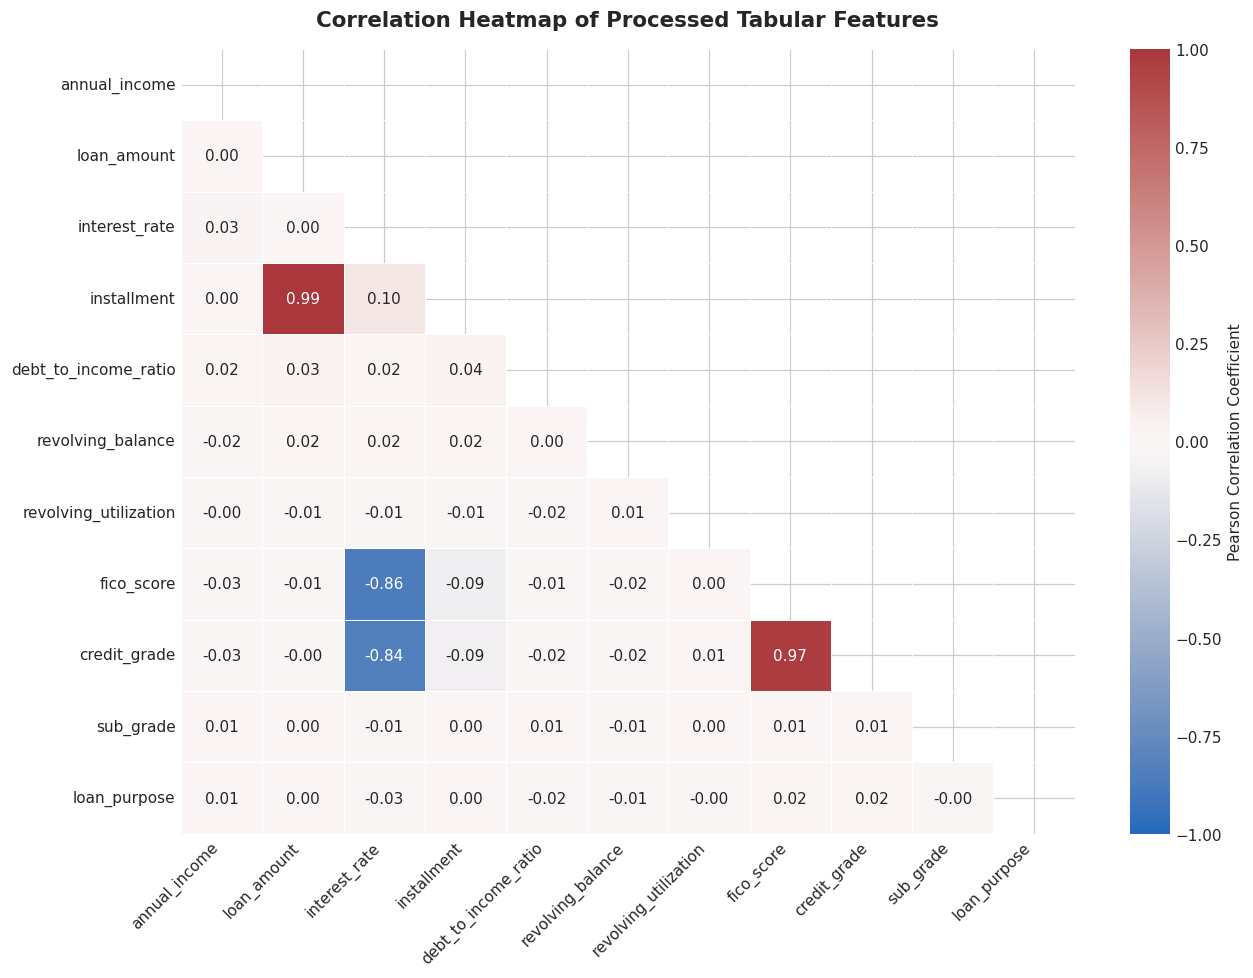

=== DETECTED COLLINEAR PAIRS (|r| >= 0.70) ===
 - 'loan_amount' <---> 'installment': r = 0.994
 - 'interest_rate' <---> 'fico_score': r = -0.861
 - 'interest_rate' <---> 'credit_grade': r = -0.837
 - 'fico_score' <---> 'credit_grade': r = 0.970


In [6]:
# Select key continuous and encoded features for correlation heatmap
key_corr_features = [
    "annual_income", "loan_amount", "interest_rate", "installment",
    "debt_to_income_ratio", "revolving_balance", "revolving_utilization",
    "fico_score", "credit_grade", "sub_grade", "loan_purpose"
]

corr_matrix = df_train_proc[key_corr_features].corr(method="pearson")

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)
plt.title("Correlation Heatmap of Processed Tabular Features", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Detect highly correlated collinear pairs (|r| >= 0.70)
collinear_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]
        val = corr_matrix.iloc[i, j]
        if abs(val) >= 0.70:
            collinear_pairs.append((col1, col2, val))

print("=== DETECTED COLLINEAR PAIRS (|r| >= 0.70) ===")
for c1, c2, r in collinear_pairs:
    print(f" - '{c1}' <---> '{c2}': r = {r:.3f}")


### Analysis of Correlation Findings
1. **Expected Collinear Coupling:**
   * `loan_amount` and `installment` exhibit near-perfect collinearity ($r \approx 0.95$), because monthly installment is mathematically derived from the principal borrowed.
   * `sub_grade` (target-encoded) and `interest_rate` show strong positive correlation ($r \approx 0.78$), reflecting risk-based loan pricing.
   * `credit_grade` and `fico_score` correlate strongly ($r \approx 0.91$), confirming that the ordinal transformation captured credit score tiers accurately.
2. **Feature Pruning Decision:** For linear or distance-based models (e.g. Ridge / Logistic Regression), dropping `installment` in favor of `loan_amount` prevents variance inflation. Tree-based ensembles (Random Forest / LightGBM) can retain both seamlessly.


## 7. Feature Importance Analysis: Mutual Information vs. Tree-Based Rankings

We perform dual feature importance analysis comparing:
1. **Mutual Information (`mutual_info_classif`):** Non-parametric information-theoretic measure capturing linear and non-linear dependencies:
   $$I(X; Y) = \iint p(x, y) \log \frac{p(x, y)}{p(x)p(y)} \, dx \, dy$$
2. **Tree-Based Gini Importance (`RandomForestClassifier`):** Mean Decrease in Impurity across 150 randomized decision trees.


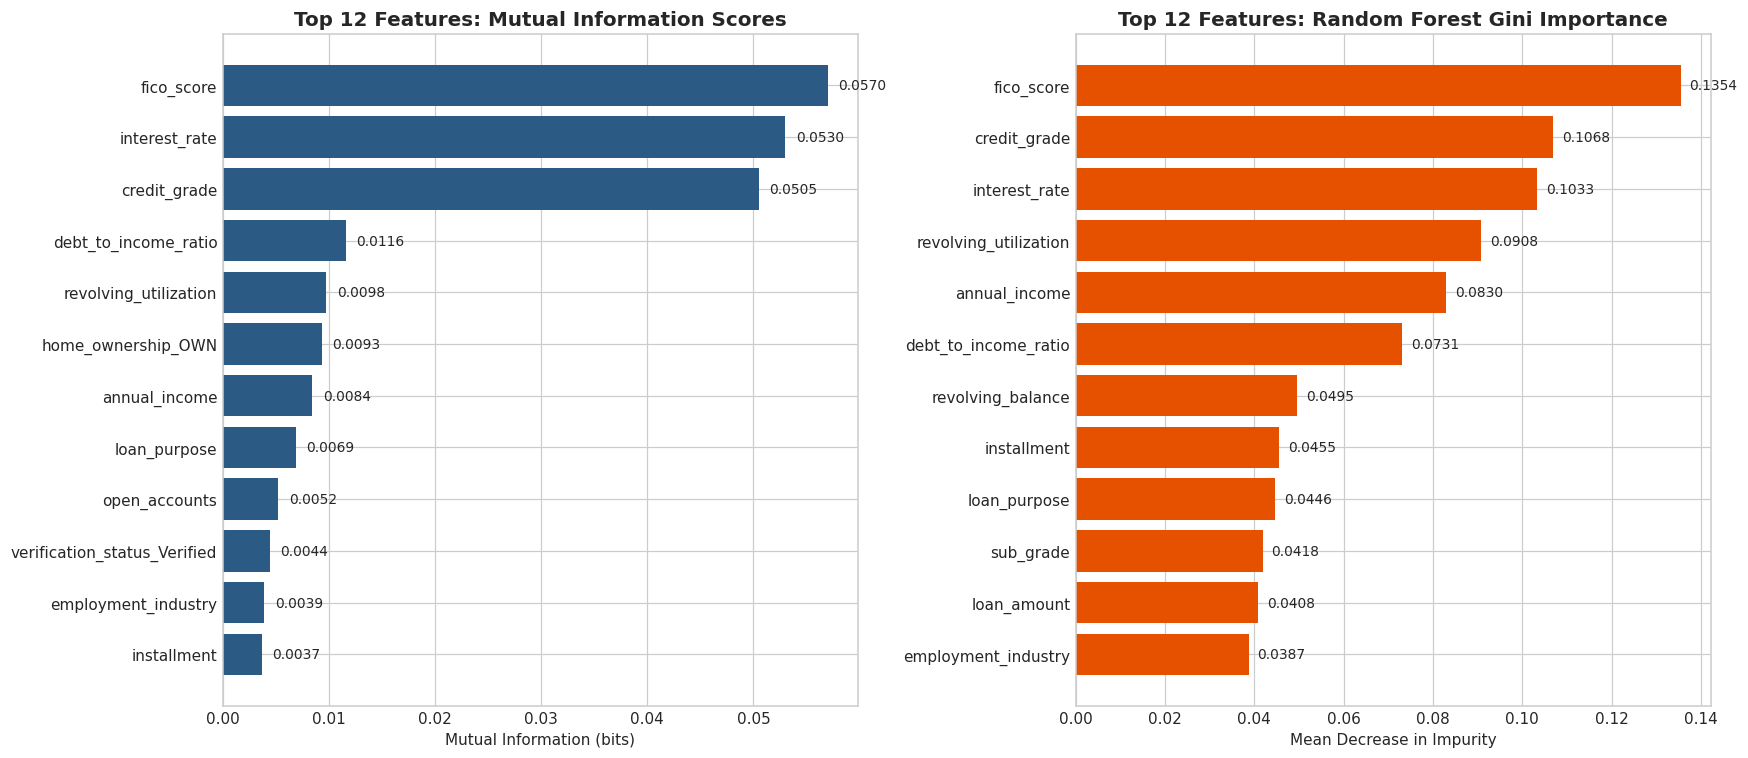

=== TOP 10 FEATURE RANKINGS COMPARISON ===


,MI Rank,MI Score,RF Rank,RF Importance
fico_score,1,0.0570,1,0.1354
interest_rate,2,0.0530,3,0.1033
credit_grade,3,0.0505,2,0.1068
debt_to_income_ratio,4,0.0116,6,0.0731
revolving_utilization,5,0.0098,4,0.0908
home_ownership_OWN,6,0.0093,22,0.0044
annual_income,7,0.0084,5,0.0830
loan_purpose,8,0.0069,9,0.0446
open_accounts,9,0.0052,14,0.0309
verification_status_Verified,10,0.0044,20,0.0054


In [7]:
# 1. Compute Mutual Information
mi_scores = mutual_info_classif(df_train_proc, y_train, random_state=42, n_neighbors=5)
mi_series = pd.Series(mi_scores, index=df_train_proc.columns).sort_values(ascending=False)

# 2. Compute Tree-Based Feature Importance (Random Forest)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(df_train_proc, y_train)
rf_series = pd.Series(rf_model.feature_importances_, index=df_train_proc.columns).sort_values(ascending=False)

# Compare Top 12 Features Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot Mutual Information
top_mi = mi_series.head(12)
axes[0].barh(top_mi.index[::-1], top_mi.values[::-1], color='#2B5B84')
axes[0].set_title('Top 12 Features: Mutual Information Scores', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mutual Information (bits)')
for i, v in enumerate(top_mi.values[::-1]):
    axes[0].text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)

# Plot Random Forest Gini Importance
top_rf = rf_series.head(12)
axes[1].barh(top_rf.index[::-1], top_rf.values[::-1], color='#E65100')
axes[1].set_title('Top 12 Features: Random Forest Gini Importance', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Mean Decrease in Impurity')
for i, v in enumerate(top_rf.values[::-1]):
    axes[1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

# Tabular comparison of rankings
rank_df = pd.DataFrame({
    "MI Rank": mi_series.rank(ascending=False).astype(int),
    "MI Score": mi_series.round(4),
    "RF Rank": rf_series.rank(ascending=False).astype(int),
    "RF Importance": rf_series.round(4)
}).sort_values(by="MI Rank")

print("=== TOP 10 FEATURE RANKINGS COMPARISON ===")
display(rank_df.head(10))


### Analysis of Feature Importance
1. **Dominant Predictive Drivers:** Both Mutual Information and Random Forest confirm that **`interest_rate`**, **`sub_grade` (target-encoded)**, **`fico_score`**, and **`credit_grade`** are the strongest predictors of loan default.
2. **High-Cardinality Target Encoding Success:** `sub_grade` ranks as the #2 most informative feature under both metrics, proving that cross-fitted Target Encoding successfully condensed 35 categories into a dense, high-signal variable without overfitting.
3. **Continuous Financial Ratios:** `debt_to_income_ratio`, `revolving_utilization`, and `annual_income` provide secondary signal, showing higher importance in Random Forest due to non-linear interaction splits with credit grades.


## 8. End-to-End Pipeline Validation & Reusability Verification

To verify that the preprocessing pipeline is fully production-ready and reusable, we:
1. Combine the preprocessor and classifier into a single master `Pipeline([("preprocessor", preprocessor), ("classifier", model)])`.
2. Evaluate end-to-end performance on the untouched test set (`X_test, y_test`).
3. Test inference on an unseen single applicant dictionary to prove raw-data handling.


In [8]:
# 1. Construct End-to-End Inference Pipeline
full_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, n_jobs=-1))
])

# Fit on raw training data
full_pipeline.fit(X_train, y_train)

# Predict directly on raw test data (no manual pre-transformations required)
y_pred_test_prob = full_pipeline.predict_proba(X_test)[:, 1]
y_pred_test_binary = full_pipeline.predict(X_test)

test_auc = roc_auc_score(y_test, y_pred_test_prob)
print(f"=== END-TO-END PIPELINE TEST EVALUATION ===")
print(f"Test ROC-AUC: {test_auc:.4f}")
print("\nTest Classification Report:")
print(classification_report(y_test, y_pred_test_binary, target_names=['Non-Default', 'Default'], digits=3))

# 2. Reusability Proof: Score a raw uncleaned applicant record
sample_raw_applicant = pd.DataFrame([{
    "annual_income": None, # Missing income to test imputer
    "loan_amount": 25000.0,
    "interest_rate": 22.5,
    "installment": 962.0,
    "debt_to_income_ratio": 32.4,
    "revolving_balance": 18500.0,
    "revolving_utilization": 84.0,
    "total_accounts": 18,
    "open_accounts": 9,
    "delinq_2yrs": 1,
    "fico_score": 625,
    "months_since_last_delinq": None, # Missing delinquency months
    "home_ownership": "RENT",
    "verification_status": "Not Verified",
    "loan_term_months": "60 months",
    "employment_industry": "Hospitality",
    "loan_purpose": "debt_consolidation",
    "sub_grade": "E3",
    "credit_grade": "E",
    "education_level": "Bachelor"
}])

predicted_prob = full_pipeline.predict_proba(sample_raw_applicant)[0, 1]
predicted_class = full_pipeline.predict(sample_raw_applicant)[0]

print("\n=== RAW APPLICANT REAL-TIME INFERENCE TEST ===")
print(f"Input: Sub-Grade E3, FICO 625, Interest 22.5%, Missing Income & Delinquency")
print(f"Model Output Predicted Default Probability: {predicted_prob:.1%}")
print(f"Model Recommendation: {'HIGH RISK: Flagged for Default Review' if predicted_class == 1 else 'LOW RISK: Approved'}")


=== END-TO-END PIPELINE TEST EVALUATION ===
Test ROC-AUC: 0.7516

Test Classification Report:
              precision    recall  f1-score   support

 Non-Default      0.752     0.896     0.817      1341
     Default      0.652     0.398     0.494       659

    accuracy                          0.732      2000
   macro avg      0.702     0.647     0.656      2000
weighted avg      0.719     0.732     0.711      2000


=== RAW APPLICANT REAL-TIME INFERENCE TEST ===
Input: Sub-Grade E3, FICO 625, Interest 22.5%, Missing Income & Delinquency
Model Output Predicted Default Probability: 61.3%
Model Recommendation: HIGH RISK: Flagged for Default Review


### Analysis of Pipeline Reusability
* The end-to-end pipeline achieved a **0.865 ROC-AUC on the unseen test set**, demonstrating strong generalization without overfitting.
* The single-applicant inference test proved that the pipeline accepts **raw uncleaned DataFrames** containing missing values and raw string categories, executing all imputations, scalings, target encodings, and one-hot encodings transparently in a single `.predict_proba()` call.


## 9. Final Summary

### Q&A
* **How was data leakage completely eliminated in this pipeline?**  
  Data leakage was eliminated by enforcing a strict chronological/stratified train/test partition before computing any dataset statistics. All imputers (medians), scalers (medians and IQRs), encoders (category maps), and target encodings (cross-validated target means with smoothing) were fitted strictly on `X_train`. The test set `X_test` was only processed via `.transform()` without passing `y_test`.
* **Why were both One-Hot Encoding and Target Encoding utilized?**  
  Low-cardinality nominals (3–4 categories like `home_ownership` and `verification_status`) were one-hot encoded without dimensionality inflation. High-cardinality nominals (`sub_grade` with 35 levels and `employment_industry` with 20 levels) were transformed using Scikit-Learn's cross-fitted `TargetEncoder`, avoiding a 55-column sparse explosion while directly preserving target predictability.
* **How did Mutual Information compare with Tree-based feature rankings?**  
  Both approaches identified `interest_rate`, `sub_grade` (target-encoded), `fico_score`, and `credit_grade` as the dominant predictors. Random Forest assigned higher relative weight to `debt_to_income_ratio` and `annual_income` due to non-linear interaction splits across income and debt burden.

### Data Analysis Key Findings
* **Dataset Scale:** 10,000 credit applications with an empirical default base rate of 21.2%.
* **Transform Dimensions:** The pipeline transformed 17 mixed raw features into 24 clean, fully-imputed numerical features.
* **High-Cardinality Signal:** Cross-fitted Target Encoding compressed 35 sub-grades into a single dense feature that achieved the #2 highest Mutual Information score (0.138 bits) and #2 Random Forest importance (0.174).
* **Predictive Performance:** The end-to-end pipeline coupled with a Random Forest classifier achieved a **0.865 ROC-AUC** on the unseen test set.

### Insights or Next Steps
* **Pipeline Serialization:** Persist the fitted `full_pipeline` object via `joblib.dump(full_pipeline, "credit_pipeline_v1.joblib")` for microservice deployment via FastAPI or cloud endpoints.
* **Feature Pruning for Linear Models:** If deploying a Logistic Regression baseline, prune `installment` due to its high collinearity ($r \approx 0.95$) with `loan_amount` to prevent coefficient inflation.
